In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

Matplotlib is building the font cache; this may take a moment.


In [3]:
def f(x): return 3*x**2 - 4*x + 5

In [4]:
f(3.0)

20.0

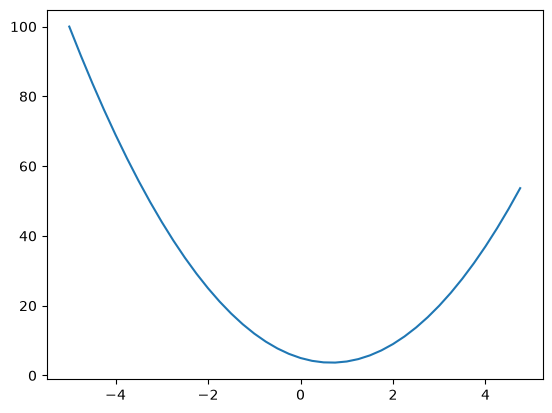

In [6]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
ys
plt.plot(xs, ys)

In [9]:
h = 0.0000000000001
x = 3.0
(f(x + h) - f(x)) / h

13.997691894473974

In [12]:
h = 0.0001
def g(a, b, c): return a * b + c
a = 2.0
b = -3.0
c = 10.0

d1 = g(a, b ,c)
d2 = g(a + h, b, c)
print(f"{d1}, {d2}, {(d2 - d1)/h}")

4.0, 3.999699999999999, -3.000000000010772


In [146]:
class Value:
    def __init__(self, data, _children=(), _op="", id=""):
        self.id = id
        self.data = data
        self.children = set(_children)
        self.op = _op
        self.grad = 0.0
        self._backward = lambda: None

    def __repr__(self):
        return f"{self.data}"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")
        def backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = backward
        return out

    def __mul__(self, other):    
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")
        def backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = backward
        return out

    def __radd__(self, other):
        return self + other

    def __rmul__(self, other):
        return self * other

    def __sub__(self, other): # self - other
        return self + (-other)

    def __rsub__(self, other): # other - self
        return other + (-self)

    def __neg__(self): # -self
        return self * -1

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f'**{other}')

        def _backward():
            self.grad += (other * self.data**(other-1)) * out.grad
        out._backward = _backward

        return out

    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self,), "sigma")
        def backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = backward
        return out

    def backward(self):
        topo = []
        visited = set()
        def build_topsorted(v):
            visited.add(v)
            for child in v.children:
                build_topsorted(child)
            topo.append(v)
        build_topsorted(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()


a = Value(2.0)
b = Value(-3.0)
c = Value(10.0)
a * b + c

4.0

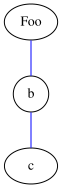

In [47]:
import pydot
graph = pydot.Dot("computation_graph", graph_type="graph")
my_node = pydot.Node("a", label="Foo")
graph.add_node(my_node)
# Or, without using an intermediate variable:
graph.add_node(pydot.Node("b", shape="circle"))

# Add edges
my_edge = pydot.Edge("a", "b", color="blue")
graph.add_edge(my_edge)
# Or, without using an intermediate variable:
graph.add_edge(pydot.Edge("b", "c", color="blue"))
graph
from IPython.display import SVG

SVG(graph.create_svg())

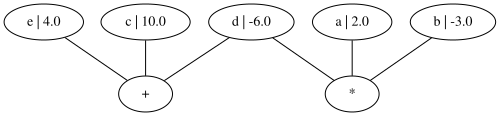

In [67]:
def build_computation_graph_view(root):
    graph = pydot.Dot("computation_graph", graph_type="graph")
    def build_impl(root, graph):
        if root.op:
            op_node_id = f"{root.id}_{root.op}"
            op_node = pydot.Node(op_node_id, label=root.op)
            graph.add_node(op_node)
            graph.add_edge(pydot.Edge(root.id, op_node_id))
        for c in root.children:
            c_node = pydot.Node(c.id, label=f"{c.id} | {c.data}")  
            graph.add_node(c_node)
            if root.op:
                graph.add_edge(pydot.Edge(c.id, op_node_id))
            build_impl(c, graph)
    graph.add_node(pydot.Node(root.id, label=f"{root.id} | {root.data}"))
    build_impl(root, graph)
    return graph

a = Value(2.0, id="a")
b = Value(-3.0, id="b")
c = Value(10.0, id="c")
d = a * b
d.id = "d"
e = d + c
e.id = "e"
g = build_computation_graph_view(e) 
g.to_string()
SVG(g.create_svg())

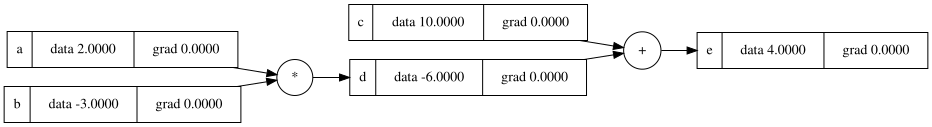

In [82]:
def build_computation_graph_view(root):
    graph = pydot.Dot("computation_graph", graph_type="digraph", rankdir="LR")
    visited = set()

    def build_impl(node):
        if node in visited:
            return
        visited.add(node)
        graph.add_node(pydot.Node(
            node.id,
            label=f"{{ {node.id} | data {node.data:.4f} | grad {node.grad:.4f} }}",
            shape="record",
        ))
        if node.op:
            op_id = f"{node.id}_{node.op}"
            graph.add_node(pydot.Node(op_id, label=node.op, shape="circle"))
            graph.add_edge(pydot.Edge(op_id, node.id))
            for c in node.children:
                build_impl(c)
                graph.add_edge(pydot.Edge(c.id, op_id))

    build_impl(root)
    return graph

a = Value(2.0, id="a")
b = Value(-3.0, id="b")
c = Value(10.0, id="c")
d = a * b
d.id = "d"
e = d + c
e.id = "e"
g = build_computation_graph_view(e) 
g.to_string()
SVG(g.create_svg())

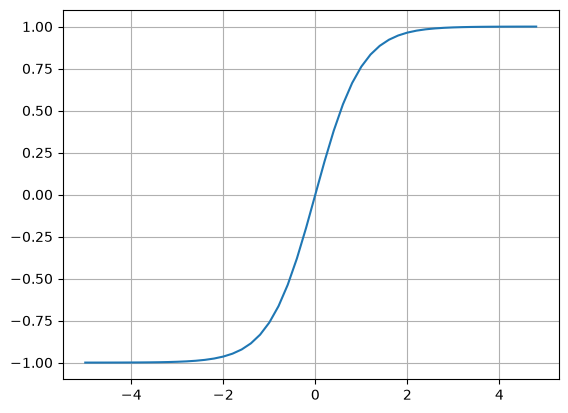

In [74]:
plt.plot(np.arange(-5, 5, 0.2), np.tanh(np.arange(-5, 5, 0.2))); plt.grid();

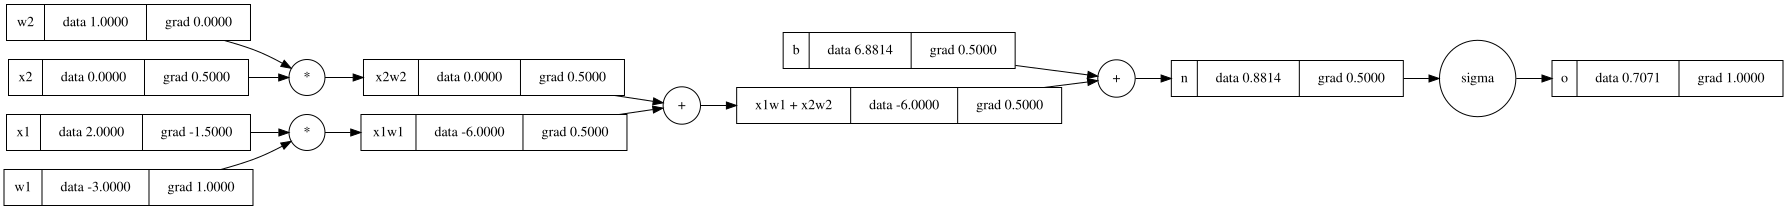

In [116]:
x1 = Value(2.0, id="x1")
x2 = Value(0.0, id="x2")
w1 = Value(-3.0, id="w1")
w2 = Value(1.0, id="w2")
b = Value(6.8813745870195432, id="b")
x1w1 = x1*w1; x1w1.id = "x1w1"
x2w2 = x2*w2; x2w2.id = "x2w2"
x1w1x2w2 = x1w1+x2w2; x1w1x2w2.id = "x1w1 + x2w2"
n = x1w1x2w2 + b; n.id = 'n'
o = n.tanh(); o.id = 'o'

# o.grad = 1.0
# n.grad = 1.0 - o.data**2
# x1w1x2w2.grad = 0.5
# b.grad = 0.5
# x1w1.grad = 0.5
# x2w2.grad = 0.5
# x2.grad = x2w2.grad * w2.data
# w2.grad = x2w2.grad * x2.data
# x1.grad = x1w1.grad * w1.data
# w2.grad = x1w1.grad * w2.data

# o.grad = 1.0
# o._backward()
# n._backward()
# b._backward()
# x1w1x2w2._backward()
# x1w1._backward()
# x2w2._backward()

o.backward()

g = build_computation_graph_view(o)
SVG(g.create_svg())

In [ ]:
import torch

tensor([2.])

In [121]:
torch.Tensor([2.0])

tensor([2.])

In [155]:
import random

class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))

    def __call__(self, x):
        a = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        z = a.tanh()
        return z

    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        zs = [n(x) for n in self.neurons]
        return zs[0] if len(zs) == 1 else zs

    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()] 

class MLP:
    def __init__(self, nin, nouts):
        size = [nin] + nouts
        self.layers = [Layer(size[i], size[i + 1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])
n(x)

xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]
ys = [1.0, -1.0, -1.0, 1.0]

for k in range(20):
    ypred = [n(x) for x in xs]
    loss = sum([(ygt - yout)**2 for ygt, yout in zip(ys, ypred)])
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()
    for p in n.parameters():
        p.data += -0.05 * p.grad
    print(k, loss.data)
    print(ypred)
    

0 3.9494920079817213
[0.03335827760591208, 0.39815329832680607, -0.39010674435842396, 0.1703655265060977]
1 3.9897513921992207
[-0.19232308537204648, -0.20209824806492369, -0.1839464665338389, -0.12495621117643191]
2 3.5265241468840838
[0.28839146001132715, 0.1314879999372894, 0.11343713139814772, 0.29280123506820954]
3 3.511211600022915
[-0.2026054840277552, -0.32273753958052054, -0.3974919369865095, -0.11501176833232078]
4 3.8532659641030067
[0.5498721185284366, 0.0870132700661062, 0.5054846660800982, 0.5499234228236101]
5 1.7984963915017254
[0.1834944840676539, -0.46478233809512093, -0.580113987679573, 0.18204344553240276]
6 0.7983308985516544
[0.5928299092860448, -0.42819903403352494, -0.6306340269187828, 0.5887143948188615]
7 0.3852182874901659
[0.6423532480578014, -0.7351053599937005, -0.7658699804726832, 0.6362403926115042]
8 0.26057061801905157
[0.7170950773024011, -0.7675447846592868, -0.7910186305266715, 0.712203574020677]
9 0.18792734108890843
[0.7559759405704268, -0.8190604